In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
torch.manual_seed(42)
X = torch.linspace(-2,2,300).reshape(-1,1)
y = 3 * X + 2 + 0.7 * torch.randn_like(X)

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size=0.20,
    random_state=42
)

In [4]:
train_dataset = TensorDataset(X_train, y_train)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

X_batch, y_batch = next(iter(train_loader))

print("Input batch shape:", X_batch.shape)
print("Target batch shape:", y_batch.shape)
print("Number of batches:", len(train_loader))

Input batch shape: torch.Size([32, 1])
Target batch shape: torch.Size([32, 1])
Number of batches: 8


In [5]:
class RegressionNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(1,8),
            nn.ReLU(),
            nn.Linear(8,1)
        )

    def forward(self, x):
        return self.network(x)

In [6]:
model = RegressionNet()

criterion = nn.MSELoss()
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)

epochs = 100
train_losses = []
test_losses = []

In [7]:
for epoch in range(epochs):
    model.train()
    batch_losses = []

    for X_batch, y_batch in train_loader:
        predictions = model(X_batch)
        loss = criterion(predictions,y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        batch_losses.append(loss.item())

    epoch_loss = sum(batch_losses) / len(batch_losses)
    train_losses.append(epoch_loss)

    model.eval()

    with torch.no_grad():
        test_predictions = model(X_test)
        test_loss = criterion(test_predictions, y_test)

    test_losses.append(test_loss.item())

    if (epoch+1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] | TrainLoss {epoch_loss:.4f} | TestLoss {test_loss.item():.4f}")

Epoch [10/100] | TrainLoss 0.5069 | TestLoss 0.6968
Epoch [20/100] | TrainLoss 0.4868 | TestLoss 0.7160
Epoch [30/100] | TrainLoss 0.4655 | TestLoss 0.7082
Epoch [40/100] | TrainLoss 0.4658 | TestLoss 0.7058
Epoch [50/100] | TrainLoss 0.4480 | TestLoss 0.7121
Epoch [60/100] | TrainLoss 0.4605 | TestLoss 0.6976
Epoch [70/100] | TrainLoss 0.4421 | TestLoss 0.6997
Epoch [80/100] | TrainLoss 0.4522 | TestLoss 0.6907
Epoch [90/100] | TrainLoss 0.4447 | TestLoss 0.6922
Epoch [100/100] | TrainLoss 0.4601 | TestLoss 0.6967


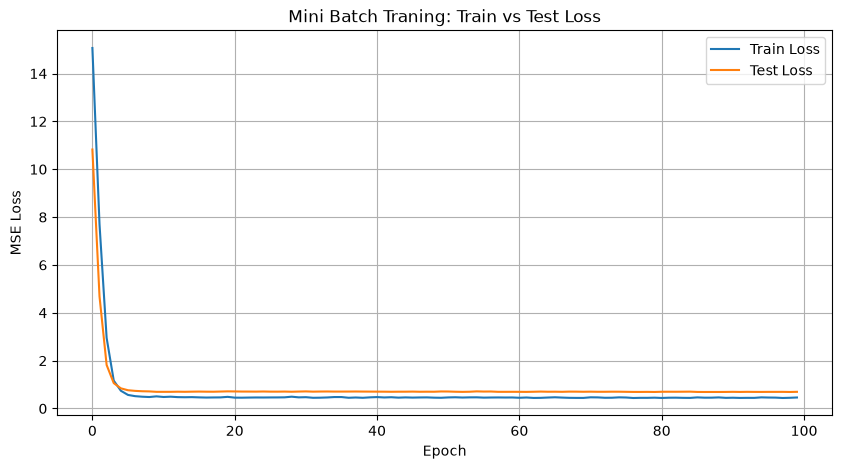

In [8]:
plt.figure(figsize=(10,5))

plt.plot(train_losses, label="Train Loss")
plt.plot(test_losses, label="Test Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Mini Batch Traning: Train vs Test Loss")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
print(f"Final train loss: {train_losses[-1]:.4f}")
print(f"Final test loss:  {test_losses[-1]:.4f}")

Final train loss: 0.4601
Final test loss:  0.6967
